# Scorer Analysis

Some plots to help interpret different scorers' performance. 

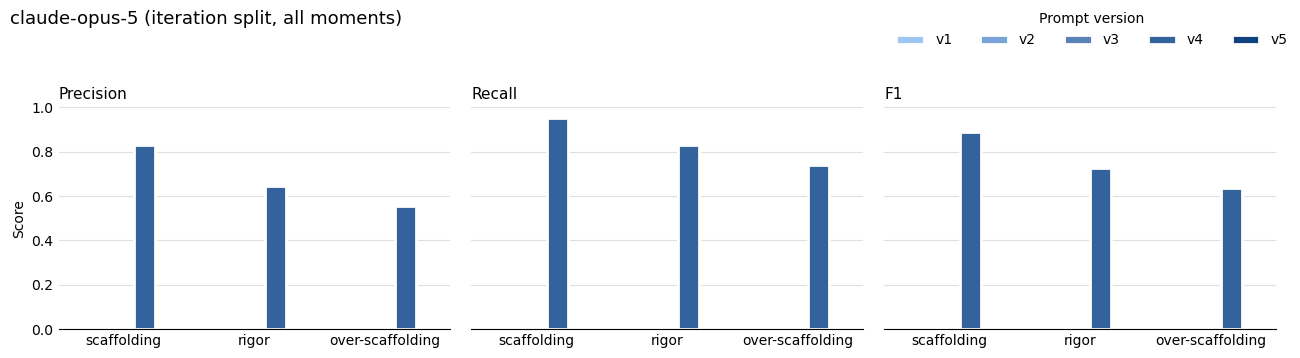

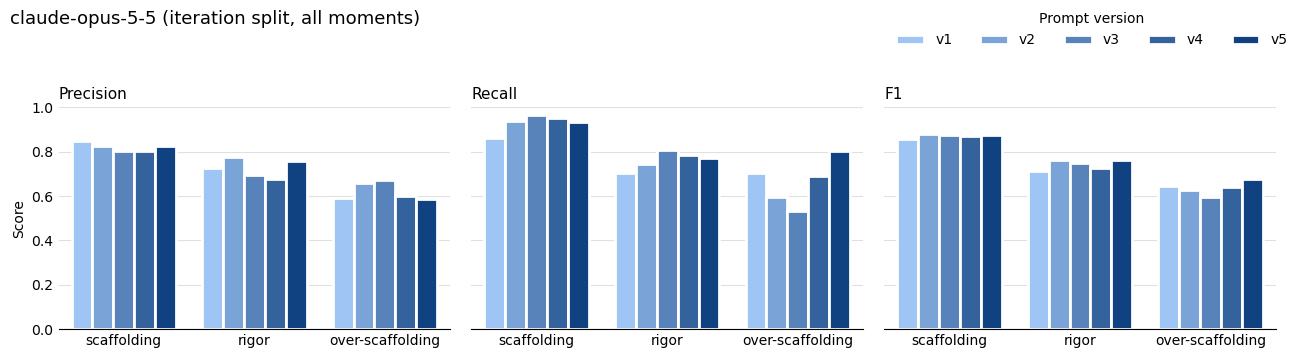

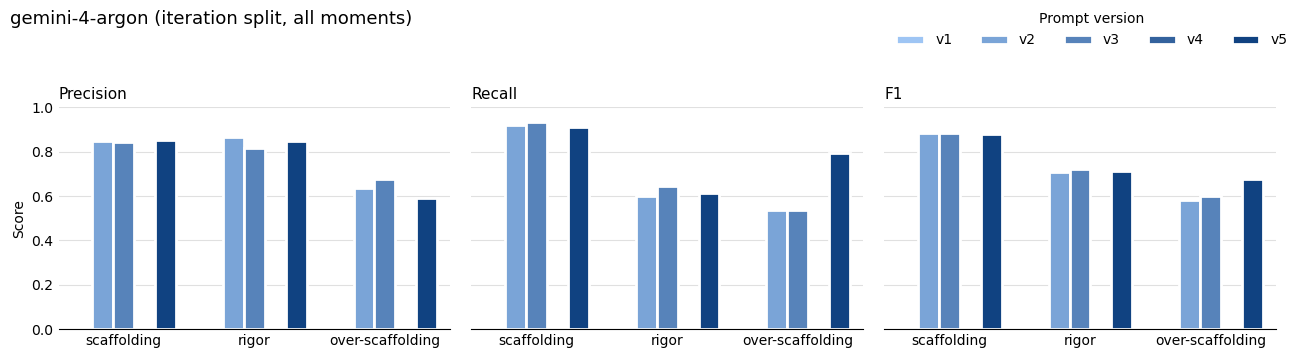

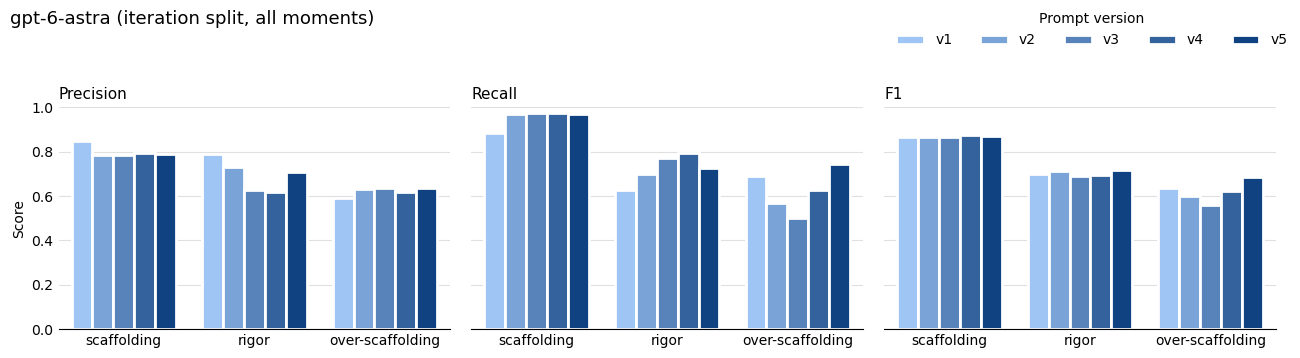

In [6]:
# plot precision, recall, and F1 as bar charts of `outputs/v2_predictions/scores.json`
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Repo root, so the path resolves whether the kernel starts there or in this folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SCORES_PATH = ROOT / "outputs/v2_predictions/scores.json"
SPLIT = "iteration"
BLOCK = "all"  # every moment with a usable prediction; "short" is the short-moment slice
METRICS = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
TASKS = ["scaffolding", "rigor", "over-scaffolding"]
# Prompt versions are ordered, so they step light -> dark along one hue.
VERSION_RAMP = LinearSegmentedColormap.from_list("version", ["#9ec5f4", "#104281"])

with open(SCORES_PATH) as f:
    scores = [r for r in json.load(f) if r["split"] == SPLIT]

# Every prompt version scored for any model, so all figures share one legend.
versions = sorted({r["prompt_version"] for r in scores}, key=int)
models = sorted({r["model"] for r in scores})


def metric_by_version(model: str, task: str, metric: str) -> list[float]:
    """The metric for each prompt version, NaN where the model has no score."""
    values = []
    for version in versions:
        record = next(
            (r for r in scores if r["model"] == model and r["prompt_version"] == version),
            None,
        )
        block = None
        if record is not None:
            block = next(t[BLOCK] for t in record["tasks"] if t["task"] == task)
        # A metric is None when undefined (e.g. precision with no predicted positives).
        value = (block or {}).get(metric)
        values.append(np.nan if value is None else value)
    return values


version_colors = {v: VERSION_RAMP(i / max(len(versions) - 1, 1)) for i, v in enumerate(versions)}

x = np.arange(len(TASKS))
bar_width = 0.8 / len(versions)

for model in models:
    fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.6), sharey=True)
    for ax, (metric, metric_label) in zip(axes, METRICS.items()):
        for i, version in enumerate(versions):
            # Every version keeps its slot, so an unscored one leaves a gap
            # rather than shifting the others along.
            offset = (i - (len(versions) - 1) / 2) * bar_width
            ax.bar(
                x + offset,
                [metric_by_version(model, task, metric)[i] for task in TASKS],
                width=bar_width,
                color=version_colors[version],
                edgecolor="white",  # surface gap between adjacent bars
                linewidth=2,
                label=f"v{version}",
            )
        ax.set_title(metric_label, loc="left", fontsize=11)
        ax.set_xticks(x, TASKS)
        ax.set_xlim(-0.5, len(TASKS) - 0.5)  # hold unscored versions' slots open
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("Score")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title="Prompt version", loc="upper right",
        ncol=len(versions), frameon=False,
    )
    fig.suptitle(f"{model} ({SPLIT} split, {BLOCK} moments)", x=0.01, ha="left", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()